# Logistic regression: how many V columns to keep?

V1 to V339 come in blocks that share the same missing pattern, and inside a block many columns are near copies.
The pruning rule (the same as `src/data_profile.py`):

1. Group V columns by identical missing count on the training rows.
2. Inside each group, go through the columns from most to fewest distinct values, and drop a column if its
   |Pearson r| with a column already kept is above a threshold **r**.

This notebook varies r from 0.50 to 1.00 in steps of 0.05 (1.00 keeps every V column) and measures how logistic
regression responds. Logistic regression is the model most affected by redundant columns, so it is the stricter
test of how far pruning can go.

**Held fixed:**

- **Features:** the raw columns only (no engineered features), minus identifiers, raw time and two empty identity
  columns, plus whichever V columns survive pruning.
- **Model:** logistic regression with C = 0.1 (the group's tuned value), `class_weight="balanced"`, lbfgs, up to
  1,000 iterations.
- **Preprocessing:** the group's linear-model recipe, re-implemented here and fitted on each fold's training rows:
  - numeric columns: median imputation, a missing indicator (for columns with any missing training value), and
    standard scaling;
  - categoricals with at most 20 levels: one-hot plus a missing column;
  - other categoricals: training-frequency encoding.
- **Validation:** the 4 expanding-window CV folds inside the training block. LR is deterministic, so one seed is
  enough.

**Pruning is redone on each fold's own training rows**, so later months never influence which columns are kept.
Each threshold is compared with r = 1.00 fold by fold, because fold-to-fold differences are larger than the
differences between thresholds.

The validation and test blocks are not used. Every fold is logged to `results/log.csv`. Finished runs are skipped,
so the notebook can be stopped and restarted.

In [1]:
import json
import time
import csv
from datetime import date
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data import load_joined

LOG_PATH = ROOT / "results" / "log.csv"
AUTHOR = "Mabel"
MODEL = "logreg"
TAG = "lr_vsweep"

N_TRAIN = 472_432                       # Context.md: first 80% by time is the training block
SEED = 0
# coarse values first, so a partial run already shows the shape of the curve
THRESHOLDS = [1.00, 0.90, 0.80, 0.75, 0.70, 0.60, 0.50, 0.95, 0.85, 0.65, 0.55]
REFERENCE_R = 1.00                      # no pruning
LR_PARAMS = {"C": 0.1, "max_iter": 1000, "class_weight": "balanced", "solver": "lbfgs"}
MAX_ONEHOT_LEVELS = 20
EXCLUDE = ["TransactionID", "TransactionDT", "TransactionDay", "isFraud", "id_12", "id_27"]

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2a78d6", "#8a8985"

## 1. Data and folds

Training block only. Training rows go into 30-day bins from the first day; fold k trains on bins 0 to k−1 and
validates on bin k.

In [2]:
df = load_joined()
assert df["TransactionDT"].is_monotonic_increasing
tr = df.iloc[:N_TRAIN].reset_index(drop=True)
del df
y = tr["isFraud"].to_numpy()

ALL_V = [f"V{i}" for i in range(1, 340)]
BASE_COLS = [c for c in tr.columns if c not in set(EXCLUDE) and c not in set(ALL_V)]
print(f"{len(tr):,} training rows; {len(BASE_COLS)} non-V input columns + up to {len(ALL_V)} V columns")

day = tr["TransactionDay"].to_numpy()
bins = (day - day.min()) // 30
FOLDS = [(np.where(bins < k)[0], np.where(bins == k)[0]) for k in range(1, bins.max() + 1)]
pd.DataFrame([{"fold": k, "train days": f"{day[a].min()}-{day[a].max()}", "train rows": len(a),
               "val days": f"{day[b].min()}-{day[b].max()}", "val rows": len(b)}
              for k, (a, b) in enumerate(FOLDS, 1)]).set_index("fold")

472,432 training rows; 91 non-V input columns + up to 339 V columns


,train days,train rows,val days,val rows
fold,,,,
1,1-30,134339,31-60,89399
2,1-60,223738,61-90,92189
3,1-90,315927,91-120,98615
4,1-120,414542,121-141,57890


## 2. V pruning at each threshold

Correlations for each missing-pattern group are computed once per fold and reused for every threshold. A column is
dropped when |r| with an already kept column is strictly above the threshold, so r = 1.00 keeps everything.

In [3]:
def kept_v_by_threshold(rows):
    sub = tr[ALL_V].iloc[rows]
    counts = sub.isna().sum()
    groups = {}
    for c in ALL_V:
        groups.setdefault(int(counts[c]), []).append(c)
    kept = {r: [] for r in THRESHOLDS}
    for cols in groups.values():
        nun = {c: sub[c].nunique(dropna=True) for c in cols}
        order = sorted(cols, key=lambda c: (-nun[c], cols.index(c)))
        corr = sub[cols].astype("float64").corr().abs() if len(cols) > 1 else None
        for r in THRESHOLDS:
            keep = []
            for c in order:
                if corr is None or not any(corr.loc[c, k] > r for k in keep):
                    keep.append(c)
            kept[r] += keep
    pos = {c: i for i, c in enumerate(ALL_V)}
    return {r: sorted(v, key=pos.get) for r, v in kept.items()}

t0 = time.time()
KEPT = {k: kept_v_by_threshold(a) for k, (a, _) in enumerate(FOLDS, 1)}
print(f"pruning done in {time.time() - t0:.0f}s")
n_kept = pd.DataFrame({f"fold {k}": {r: len(v) for r, v in KEPT[k].items()} for k in KEPT}).sort_index()
n_kept.index.name = "r"
n_kept

pruning done in 11s


,fold 1,fold 2,fold 3,fold 4
r,,,,
0.50,90,96,97,98
0.55,98,103,106,103
0.60,102,112,116,114
0.65,114,121,120,119
0.70,124,129,131,129
0.75,141,141,138,142
0.80,152,158,162,164
0.85,181,185,189,193
0.90,207,225,230,230


## 3. Preprocessing, model and logging

In [4]:
def is_cat(s):
    return isinstance(s.dtype, pd.CategoricalDtype) or pd.api.types.is_string_dtype(s) or s.dtype == object

class LinearPrep:
    # Fitted on training rows only; output is a float32 array with no NaN.
    def fit(self, d):
        self.numeric = [c for c in d.columns if not is_cat(d[c])]
        cats = [c for c in d.columns if is_cat(d[c])]
        x = d[self.numeric].to_numpy(dtype="float64")
        miss = np.isnan(x)
        with np.errstate(all="ignore"):
            med = np.nanmedian(x, axis=0)
        self.med = np.where(np.isnan(med), 0.0, med)
        filled = np.where(miss, self.med, x)
        self.mean = filled.mean(0)
        sd = filled.std(0)
        self.sd = np.where(sd > 0, sd, 1.0)
        self.ind = [c for c, m in zip(self.numeric, miss.any(0)) if m]
        self.onehot, self.freq = {}, {}
        for c in cats:
            s = d[c].astype("string")
            levels = sorted(s.dropna().unique())
            if len(levels) <= MAX_ONEHOT_LEVELS:
                self.onehot[c] = levels
            else:
                self.freq[c] = s.fillna("__nan__").value_counts(normalize=True).to_dict()
        return self

    def transform(self, d):
        x = d[self.numeric].to_numpy(dtype="float64")
        parts = [((np.where(np.isnan(x), self.med, x) - self.mean) / self.sd).astype("float32"),
                 d[self.ind].isna().to_numpy().astype("float32")]
        for c, levels in self.onehot.items():
            s = d[c].astype("string")
            parts.append(np.column_stack([(s == lv).fillna(False).to_numpy() for lv in levels]
                                         + [s.isna().to_numpy()]).astype("float32"))
        for c, f in self.freq.items():
            s = d[c].astype("string").fillna("__nan__")
            parts.append(s.map(f).astype("float64").fillna(0.0).to_numpy().astype("float32")[:, None])
        return np.hstack(parts)

LOG_COLS = ["date", "author", "model", "feature_set", "cv_scheme", "split", "seed", "params",
            "pr_auc", "auroc", "precision", "recall", "recall_top1pct", "runtime_s"]

def read_log():
    if not LOG_PATH.exists():
        return pd.DataFrame()
    log = pd.read_csv(LOG_PATH)
    log = log[(log["model"] == MODEL) & (log["author"] == AUTHOR)].copy()
    if log.empty:
        return log
    p = pd.json_normalize(log["params"].map(json.loads).tolist()).set_index(log.index)
    return log.join(p[[c for c in p.columns if c not in log.columns]])

def log_run(row):
    new = not LOG_PATH.exists() or LOG_PATH.stat().st_size == 0
    if not new:
        with open(LOG_PATH) as f:
            assert next(csv.reader(f)) == LOG_COLS, "results/log.csv has unexpected columns"
    with open(LOG_PATH, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=LOG_COLS)
        if new:
            w.writeheader()
        w.writerow({k: row.get(k) for k in LOG_COLS})

def recall_top1pct(y_true, score):
    k = int(np.ceil(0.01 * len(score)))
    return y_true[np.argsort(-score, kind="stable")[:k]].sum() / y_true.sum()

def set_name(r):
    return f"raw_vr{round(r * 100):03d}"

## 4. Run the sweep

About 1 to 2 minutes per fit, 44 fits. The order is threshold-major and coarse values come first, so stopping
early still leaves a usable curve.

In [5]:
done = set(read_log().get("run_key", pd.Series(dtype=str)))
for r in THRESHOLDS:
    for k, (a, b) in enumerate(FOLDS, 1):
        key = f"{TAG}|{set_name(r)}|fold{k}|seed{SEED}"
        if key in done:
            continue
        cols = BASE_COLS + KEPT[k][r]
        t0 = time.time()
        prep = LinearPrep().fit(tr[cols].iloc[a])
        Xa, Xb = prep.transform(tr[cols].iloc[a]), prep.transform(tr[cols].iloc[b])
        clf = LogisticRegression(random_state=SEED, **LR_PARAMS).fit(Xa, y[a])
        score = clf.predict_proba(Xb)[:, 1]
        n_iter = int(clf.n_iter_[0])
        params = {"run_key": key, "tag": TAG, "fold": k, "features": "raw", "v_threshold": r,
                  "v_pruning_fit_on": "fold training rows", "n_v_kept": len(KEPT[k][r]),
                  "n_inputs": Xa.shape[1], "n_iter": n_iter, "converged": n_iter < LR_PARAMS["max_iter"],
                  **{p: v for p, v in LR_PARAMS.items()}}
        log_run({"date": date.today().isoformat(), "author": AUTHOR, "model": MODEL, "feature_set": set_name(r),
                 "cv_scheme": "time", "split": "cv", "seed": SEED, "params": json.dumps(params),
                 "pr_auc": average_precision_score(y[b], score), "auroc": roc_auc_score(y[b], score),
                 "recall_top1pct": recall_top1pct(y[b], score), "runtime_s": round(time.time() - t0, 1)})
        print(f"  r={r:.2f} fold {k}: PR-AUC {average_precision_score(y[b], score):.4f}, "
              f"{Xa.shape[1]} inputs, {n_iter} iters ({time.time() - t0:.0f}s)")

  r=1.00 fold 1: PR-AUC 0.3996, 817 inputs, 554 iters (6s)


  r=1.00 fold 2: PR-AUC 0.4294, 829 inputs, 604 iters (11s)


  r=1.00 fold 3: PR-AUC 0.4275, 829 inputs, 678 iters (18s)


  r=1.00 fold 4: PR-AUC 0.4511, 829 inputs, 698 iters (25s)


  r=0.90 fold 1: PR-AUC 0.3966, 562 inputs, 414 iters (4s)


  r=0.90 fold 2: PR-AUC 0.4250, 604 inputs, 507 iters (7s)


... (34 outputs left out)

  r=0.55 fold 1: PR-AUC 0.3708, 369 inputs, 356 iters (3s)


  r=0.55 fold 2: PR-AUC 0.4020, 385 inputs, 394 iters (5s)


  r=0.55 fold 3: PR-AUC 0.3863, 390 inputs, 361 iters (6s)


  r=0.55 fold 4: PR-AUC 0.4316, 385 inputs, 398 iters (9s)


## 5. Results

Read back from `results/log.csv`.

- **Δ vs r = 1.00:** mean of (this threshold − no pruning) over the 4 folds, with the standard error of that mean.
- **folds better:** in how many folds this threshold beat no pruning.
- **converged:** whether every fit finished before the iteration limit. A fit that stopped early can score lower
  for reasons that have nothing to do with the columns.

In [6]:
log = read_log()
sw = log[(log["split"] == "cv") & (log["tag"] == TAG)].copy()
sw["fold"] = sw["fold"].astype(int)
ref = sw[sw["v_threshold"] == REFERENCE_R].set_index("fold")["pr_auc"]
rows = []
for r in sorted(sw["v_threshold"].unique()):
    g = sw[sw["v_threshold"] == r].set_index("fold")
    common = g.index.intersection(ref.index)
    d = g.loc[common, "pr_auc"] - ref.loc[common]
    rows.append({"r": r, "V kept (avg)": g["n_v_kept"].mean(), "inputs (avg)": g["n_inputs"].mean(),
                 "folds": len(g), "mean PR-AUC": g["pr_auc"].mean(), "mean AUROC": g["auroc"].mean(),
                 "Δ vs r=1.00": d.mean() if r != REFERENCE_R else 0.0,
                 "SE of Δ": d.std() / np.sqrt(len(d)) if r != REFERENCE_R and len(d) > 1 else np.nan,
                 "folds better": f"{int((d > 0).sum())}/{len(d)}" if r != REFERENCE_R else "",
                 "converged": bool(g["converged"].all()), "avg fit s": g["runtime_s"].mean()})
results = pd.DataFrame(rows).set_index("r")
results.round(4)

,V kept (avg),inputs (avg),folds,mean PR-AUC,mean AUROC,Δ vs r=1.00,SE of Δ,folds better,converged,avg fit s
r,,,,,,,,,,
0.50,95.25,369.25,4,0.3871,0.8439,-0.0398,0.0103,0/4,True,5.600
0.55,102.50,382.25,4,0.3977,0.8438,-0.0292,0.0045,0/4,True,5.575
0.60,111.00,397.00,4,0.4136,0.8453,-0.0133,0.0052,0/4,True,5.750
0.65,118.50,410.75,4,0.4213,0.8471,-0.0056,0.0022,0/4,True,6.250
0.70,128.25,427.25,4,0.4230,0.8465,-0.0038,0.0050,2/4,True,6.200
0.75,140.50,448.75,4,0.4266,0.8478,-0.0002,0.0062,2/4,True,6.575
0.80,159.00,484.25,4,0.4310,0.8479,0.0041,0.0063,2/4,True,7.175
0.85,187.00,532.50,4,0.4267,0.8471,-0.0002,0.0025,2/4,True,7.600
0.90,223.00,598.00,4,0.4239,0.8489,-0.0030,0.0016,1/4,True,9.025


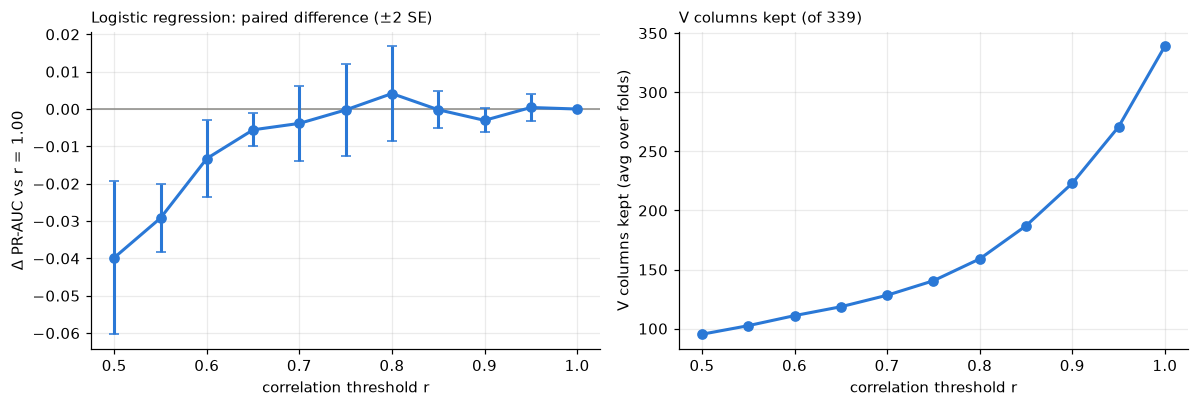

best threshold: r = 0.80 (mean PR-AUC 0.4310)
lowest threshold within 2 SE of the best: r = 0.65 (118 V columns on average)


In [7]:
complete = results[results["folds"] == len(FOLDS)]
if len(complete) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    x = complete.index.to_numpy()
    ax = axes[0]
    ax.axhline(0, color=GREY, lw=1)
    ax.errorbar(x, complete["Δ vs r=1.00"], yerr=2 * complete["SE of Δ"].fillna(0), color=BLUE, lw=2,
                marker="o", ms=6, capsize=3)
    ax.set_xlabel("correlation threshold r"); ax.set_ylabel("Δ PR-AUC vs r = 1.00")
    ax.set_title("Logistic regression: paired difference (±2 SE)", loc="left", fontsize=10)
    ax = axes[1]
    ax.plot(x, complete["V kept (avg)"], color=BLUE, lw=2, marker="o", ms=6)
    ax.set_xlabel("correlation threshold r"); ax.set_ylabel("V columns kept (avg over folds)")
    ax.set_title("V columns kept (of 339)", loc="left", fontsize=10)
    fig.tight_layout(); plt.show()

    best = complete["mean PR-AUC"].idxmax()
    best_pr = complete.loc[best, "mean PR-AUC"]
    # lowest threshold whose paired difference from the best is within 2 standard errors
    piv = sw[sw["v_threshold"].isin(complete.index)].pivot(index="fold", columns="v_threshold", values="pr_auc")
    gap = piv.sub(piv[best], axis=0)
    ok = [r for r in complete.index if gap[r].mean() + 2 * gap[r].std() / np.sqrt(len(gap)) >= 0]
    print(f"best threshold: r = {best:.2f} (mean PR-AUC {best_pr:.4f})")
    print(f"lowest threshold within 2 SE of the best: r = {min(ok):.2f} "
          f"({complete.loc[min(ok), 'V kept (avg)']:.0f} V columns on average)")

In [8]:
# per-fold PR-AUC, to see whether a threshold helps only in some months
sw.pivot(index="v_threshold", columns="fold", values="pr_auc").add_prefix("fold ").round(4)

fold,fold 1,fold 2,fold 3,fold 4
v_threshold,,,,
0.50,0.3872,0.3713,0.3749,0.4148
0.55,0.3708,0.4020,0.3863,0.4316
0.60,0.3930,0.4270,0.4042,0.4302
0.65,0.3972,0.4277,0.4165,0.4438
0.70,0.4056,0.4328,0.4167,0.4370
0.75,0.3996,0.4463,0.4162,0.4444
0.80,0.4007,0.4522,0.4238,0.4474
0.85,0.4032,0.4340,0.4228,0.4468
0.90,0.3966,0.4250,0.4288,0.4449


## 6. Result: r = 0.75

Mean PR-AUC over the 4 folds, from the table in section 5 (read from the log):

| r | V kept (mean over folds) | Mean PR-AUC | Change vs r = 1.00 | SE | Folds better |
| --- | --- | --- | --- | --- | --- |
| 1.00 | 339 | 0.4269 | — | — | — |
| 0.90 | 223 | 0.4239 | −0.0030 | 0.0016 | 1 / 4 |
| 0.80 | 159 | 0.4310 | +0.0041 | 0.0063 | 2 / 4 |
| **0.75** | **141** | **0.4266** | **−0.0002** | **0.0062** | **2 / 4** |
| 0.70 | 128 | 0.4230 | −0.0038 | 0.0050 | 2 / 4 |
| 0.65 | 119 | 0.4213 | −0.0056 | 0.0022 | 0 / 4 |
| 0.60 | 111 | 0.4136 | −0.0133 | 0.0052 | 0 / 4 |
| 0.50 | 95 | 0.3871 | −0.0398 | 0.0103 | 0 / 4 |

- **From 1.00 down to 0.70, every change is within noise:** each is within about one standard error of zero, and
  each threshold beats no pruning in one or two of the four folds.
- **From 0.65 down, PR-AUC is lower than with no pruning in every fold,** and the loss grows quickly (−0.0133 at
  0.60, −0.0398 at 0.50). The automatic rule in section 5 still counts 0.65 as within two standard errors of the
  best threshold, but losing in all four folds is the start of the decline, so it isn't a safe choice.
- **Decision: r = 0.75.** It is the most aggressive threshold that keeps a margin above where the losses start, and
  it removes 58% of the V columns (339 → 141 on average) at no measurable cost.
- AUROC barely moves across the whole range (0.8439 to 0.8489), which is why the decision uses PR-AUC.

This replaces the first proposal in `config/features.yaml` (r = 0.90 on the whole training block, from
`src/data_profile.py`), which pruned less and scored no better. On the whole training block, r = 0.75 keeps 142 V
columns; `notebooks/01_eda.ipynb` section 13 applies it. The group has agreed to use r = 0.75 for every model.
